In [1]:

!pip install tensorflow-gpu==2.3.0 keras==2.4.3 matplotlib scikit-image==0.17.2 imageio scipy==1.4.1



Looking in indexes: http://mirrors.aliyun.com/pypi/simple


## **Importing Libraries**  

In [2]:
!pip install opencv-python

Looking in indexes: http://mirrors.aliyun.com/pypi/simple


In [3]:
#Import all the required libraries

# Data Science 
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

# Deep Learning 
import tensorflow as tf

# Image Preprocess 
import skimage
from skimage.transform import resize
import imageio
import cv2
import PIL
from PIL import Image

# OS Navigation 
import glob
import os
import pathlib
import sys
from sys import platform
import time

# Ignore Warnings 
import warnings
warnings.filterwarnings("ignore")
from tensorflow.keras.preprocessing import image_dataset_from_directory
from keras.utils.vis_utils import plot_model

2025-07-14 14:06:58.019244: I tensorflow/stream_executor/platform/default/dso_loader.cc:48] Successfully opened dynamic library libcudart.so.10.1


In [4]:
# Printing all the version of require libraries 
print("Numpy : {}" .format(np.__version__))
print("matplotlib : {}" .format(matplotlib.__version__))
print("tensorflow : {}" .format(tf.__version__))
print("skimage : {}" .format(skimage.__version__))
print("imageio : {}" .format(imageio.__version__))
print("PIL : {}" .format(PIL.__version__))
print("sys : {}" .format(sys.version))

Numpy : 1.18.5
matplotlib : 3.4.3
tensorflow : 2.3.0
skimage : 0.17.2
imageio : 2.35.1
PIL : 10.4.0
sys : 3.8.10 (default, Jun  4 2021, 15:09:15) 
[GCC 7.5.0]


## **Data Loading**

In [11]:
import cv2
import os
import shutil
import tensorflow as tf
import pathlib

# 定义外层目录路径
outer_dir = "/root/autodl-tmp/MRI-STYLE-TRANSFER-USING-GAN-main/Tr1/all_images_pMRI"
inner_dir = os.path.join(outer_dir, "all_images_pMRI")

# 检查内层目录是否存在
if os.path.exists(inner_dir):
    # 遍历内层目录的所有文件并移动到外层目录
    for filename in os.listdir(inner_dir):
        src = os.path.join(inner_dir, filename)
        dst = os.path.join(outer_dir, filename)
        shutil.move(src, dst)
    
    # 删除空的内层目录
    os.rmdir(inner_dir)
    print("嵌套的文件夹内容已成功移出！")
else:
    print("内层文件夹不存在，操作终止。")

base_dir = "Tr1/all_images_pMRI"
print(f"Processing directory: {base_dir}")
file_name = "pMRI_slice150.png"

# 生成绝对路径，避免路径解析问题
file_path = os.path.abspath(os.path.join(base_dir, file_name))

# 读取图像
sample = cv2.imread(file_path, cv2.IMREAD_UNCHANGED)

if sample is None:
    print(f"Error: Failed to load image at {file_path}")
else:
    print("Image loaded successfully!")
    print("Image shape:", sample.shape)
import os
print("File exists:", os.path.exists(file_path))




####
# 定义外层目录路径
outer_dir = "/root/autodl-tmp/MRI-STYLE-TRANSFER-USING-GAN-main/Tr2/all_images_iMRI"
inner_dir = os.path.join(outer_dir, "all_images_iMRI")

# 检查内层目录是否存在
if os.path.exists(inner_dir):
    # 遍历内层目录的所有文件并移动到外层目录
    for filename in os.listdir(inner_dir):
        src = os.path.join(inner_dir, filename)
        dst = os.path.join(outer_dir, filename)
        shutil.move(src, dst)
    
    # 删除空的内层目录
    os.rmdir(inner_dir)
    print("嵌套的文件夹内容已成功移出！")
else:
    print("内层文件夹不存在，操作终止。")


base_dir = "Tr2/all_images_iMRI"
print(f"Processing directory: {base_dir}")
file_name = "iMRI_slice150.png"

# 生成绝对路径，避免路径解析问题
file_path = os.path.abspath(os.path.join(base_dir, file_name))

# 读取图像
sample = cv2.imread(file_path, cv2.IMREAD_UNCHANGED)

if sample is None:
    print(f"Error: Failed to load image at {file_path}")
else:
    print("Image loaded successfully!")
    print("Image shape:", sample.shape)
import os
print("File exists:", os.path.exists(file_path))

内层文件夹不存在，操作终止。
Processing directory: Tr1/all_images_pMRI
Image loaded successfully!
Image shape: (256, 256, 4)
File exists: True
嵌套的文件夹内容已成功移出！
Processing directory: Tr2/all_images_iMRI
Image loaded successfully!
Image shape: (256, 256, 4)
File exists: True


In [23]:
# setting path to the iMRI an pMRI datasets
iMRI_path = pathlib.Path('Tr1')   # pMRI
pMRI_path = pathlib.Path('Tr2')   # iMRI

Mask_path = pathlib.Path('Tr_mask/all_masks_iMRI')  # 你刚刚输出的掩码PNG


In [ ]:
IMG_HEIGHT = 256
IMG_WIDTH = 256

def load_iMRI_and_mask(img_path):
    """
    img_path: 某个 iMRI png 的路径 (tf.string)，例如 'Tr2/all_images_iMRI/iMRI_slice_050.png'
    返回: (iMRI_img, mask_img)，都是 [H,W,1]、float32、0~1
    """
    # 读取 iMRI
    img_bytes = tf.io.read_file(img_path)
    img = tf.image.decode_png(img_bytes, channels=1)
    img = tf.image.resize(img, [IMG_HEIGHT, IMG_WIDTH])
    img = tf.cast(img, tf.float32) / 255.0   # -> [0,1]

    # 构造 mask 路径：根据你的命名来写
    # 例子：把 'all_images_iMRI/iMRI_slice_050.png' 替换成 'all_masks_iMRI/mask_slice_050.png'
    mask_path = tf.strings.regex_replace(
        img_path,
        pattern=r"all_images_iMRI/iMRI_slice_",
        rewrite="all_masks_iMRI/mask_slice_"
    )

    mask_bytes = tf.io.read_file(mask_path)
    mask = tf.image.decode_png(mask_bytes, channels=1)
    mask = tf.image.resize(mask, [IMG_HEIGHT, IMG_WIDTH])
    mask = tf.cast(mask > 0, tf.float32)   # 二值 0/1

    return img, mask


def load_pMRI(img_path):
    img_bytes = tf.io.read_file(img_path)
    img = tf.image.decode_png(img_bytes, channels=1)
    img = tf.image.resize(img, [IMG_HEIGHT, IMG_WIDTH])
    img = tf.cast(img, tf.float32) / 255.0
    return img


### **Basic EDA**        

In [20]:
# Reading sample image to check dimension
base_dir = 'Tr1/all_images_pMRI'
sample = cv2.imread(str(base_dir)+"/pMRI_slice150.png")
sample.shape

(256, 256, 3)

In [27]:
# verifying the image count in the dataset
iMRI_image_count = len(list(iMRI_path.glob('*/*.png'))) # all the data inside the dataset are in PNG format
pMRI_image_count = len(list(pMRI_path.glob('*/*.png')))

print('Number of images in iMRI directory --> ',iMRI_image_count)
print('Number of images in pMRI directory --> ',pMRI_image_count)

Number of images in T1 directory -->  101
Number of images in T2 directory -->  103


### **Basic Data Visualization**

2
Found 103 files belonging to 2 classes.


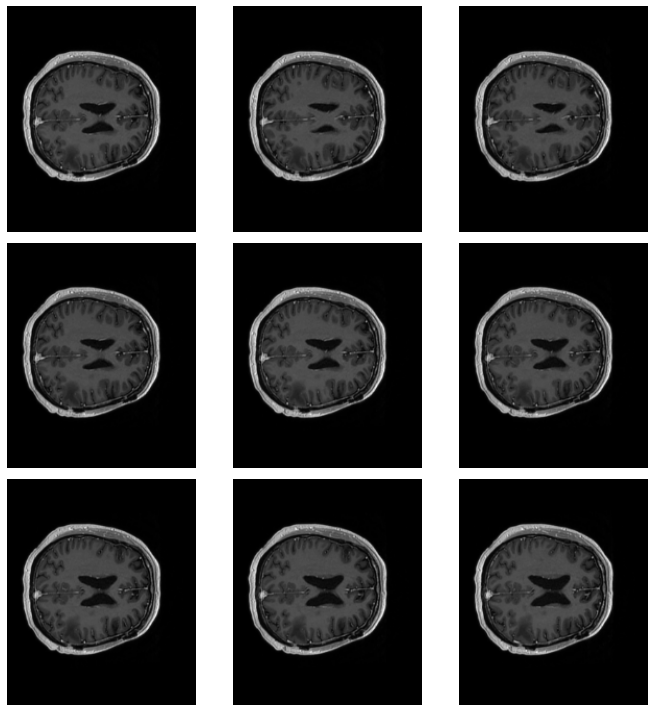

In [28]:
import os
import shutil
print(len(os.listdir(iMRI_path)))
 # Setting input image sizes 
IMG_HEIGHT = 217
IMG_WIDTH = 181

# Loading iMRI images
images_iMRI = image_dataset_from_directory(iMRI_path, seed = 123, shuffle = False,
                                         image_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=32)
# # Visualizing data from iMRI dataset
# plt.figure(figsize=(10, 10))
# for images in images_iMRI.take(1):
#   print("iMRI data examples")
#   for i in range(9):
#     ax = plt.subplot(3, 3, i + 1)
#     plt.imshow(images[i].numpy().astype("uint8"))
    
# fig, axes = plt.subplots(3, 3, figsize=(10, 10))
# for i, ax in enumerate(axes.flat):
#     if i < images_iMRI.shape[0]:
#         img = images_iMRI[i].numpy().astype("uint8")
#         ax.imshow(img)
#         ax.axis('off')
#     else:
#         ax.axis('off')

# plt.tight_layout()
# plt.show()

# for images in images_iMRI.take(1):  # 获取第一个批次
#     # 提取图像数据
#     images_data = images.numpy().astype("uint8")

for images, _ in images_iMRI.take(1):  # 提取第一个批次的图像数据
    images_data = images.numpy().astype("uint8")
    
# 显示图像
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for i, ax in enumerate(axes.flat):
    if i < images_data.shape[0]:
        img = images_data[i].astype("uint8")
        ax.imshow(img)
        ax.axis('off')
    else:
        ax.axis('off')

plt.tight_layout()
plt.show()

Found 103 files belonging to 2 classes.
T2 data examples



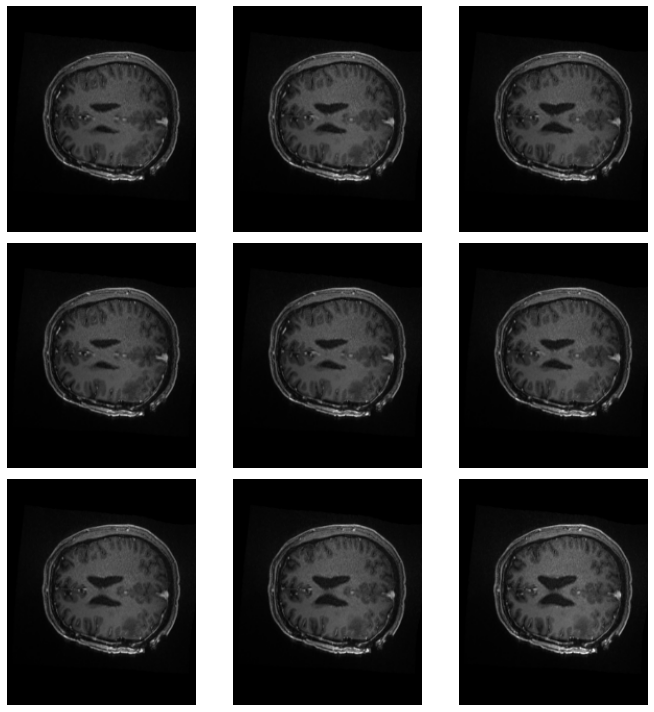

In [29]:
import os
import shutil

        

# 加载 pMRI 数据集
IMG_HEIGHT, IMG_WIDTH = 217, 181  # 图像的目标大小
images_pMRI = image_dataset_from_directory(
    pMRI_path,
    seed=123,
    shuffle=False,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=64  # 每批次加载 64 张图像
)


# Visualizing data from pMRI dataset
plt.figure(figsize=(10, 10))

# 提取第一个批次的图像数据
for images, _ in images_pMRI.take(1):  # 提取图像和标签
    print("pMRI data examples\n")
    for i in range(9):  # 只显示前 9 张图像
        ax = plt.subplot(3, 3, i + 1)
        img = images[i].numpy().astype("uint8")  # 提取第 i 张图像并转换为 NumPy 数组
        ax.imshow(img)  # 显示图像
        ax.axis('off')  # 隐藏坐标轴
plt.tight_layout()
plt.show()

In [30]:
# Checking range of values of the pixels making up the image in iMRI data
image_batch = next(iter(images_iMRI))
first_image = image_batch[0]
print("iMRI data pixel value range: ", np.min(first_image), np.max(first_image))

T1 data pixel value range:  0.0 254.39435


In [31]:
# Checking range of values of the pixels making up the image in pMRI data
image_batch = next(iter(images_pMRI))
first_image = image_batch[0]
print("pMRI data pixel value range: ", np.min(first_image), np.max(first_image))

T2 data pixel value range:  0.0 250.11902


# **Data Preprocessing**
1. Data Normalization
2. Data Resizing
3. Data Reshaping
4. Batch and Shuffle Data
5. Data Augmentation

### **Image Processing:**          

As part of image preprocessing following steps will be performed on the data set

1. Reshape, shuffle, batch and convert the image to grayscale (returned as iMRI and pMRI)
  
  *Reshaping the image size from base size (217 x 181) to (256 x 256) using batch size of 1* 
2. Normalize the image (Data Re-scaling in the range of [-1,1])
3. Data Augmentation (Here performing random horizontal flip on the image)

### **1. Performing image load from directory, reshape, shuffle, batch and convert to grayscale (Preprocessing-1)**
 - **Data Resizing, Data Reshaping, Batch and Shuffle Data During Load**  
 - **Reshape the data to a single channel**

In [32]:
 # method to load the images from the given directory path
def data_load(directory):
  image = tf.keras.preprocessing.image_dataset_from_directory(directory, 
                                                    labels='inferred', 
                                                    label_mode='int', 
                                                    class_names=None, 
                                                    color_mode='grayscale', 
                                                    batch_size=1, 
                                                    image_size=(256, 256), 
                                                    shuffle= True, 
                                                    seed=42, 
                                                    validation_split=None, 
                                                    subset=None, 
                                                    interpolation='bilinear', 
                                                    follow_links=False)
  return image

In [33]:
# performing image load from directory, reshape, shuffle, batch and convert to grayscale (preprocessing-1)
iMRI = data_load(iMRI_path)
pMRI = data_load(pMRI_path)

Found 103 files belonging to 2 classes.
Found 103 files belonging to 2 classes.


### **2. Data Normalization (Preprocessing-2)**

In [34]:
# method to normalize single channel image (preprocessing-2)
def normalize(image):
  image = tf.cast(image, tf.float32)
  image = (image - 127.5) /127.5
  return image

### **3. Data Augmentation (Preprocessing-3)**    

In [35]:
# perform random horizontal flip and normalize the image (preprocessing-3)
def preprocess_image_train(image, label):
  image = tf.image.random_flip_left_right(image)
  image = normalize(image)
  return image

In [36]:
# preprocessing the data under iMRI and pMRI
iMRI = iMRI.map(preprocess_image_train)
pMRI = pMRI.map(preprocess_image_train)

### **Tensor Specifications for the Preprocessed images**

In [37]:
# printing the tensor specifications for the preprocessed images
print(iMRI)
print(pMRI)

<MapDataset shapes: (None, 256, 256, 1), types: tf.float32>
<MapDataset shapes: (None, 256, 256, 1), types: tf.float32>


### **Input Pipeline is obtained**

In [38]:
# iterating through all the preprocessed images and caching them
sample_pMRI = next(iter(iMRI))
sample_iMRI = next(iter(pMRI))

In [39]:
print("Shape of individual Sample pMRI image: ",sample_pMRI[0].shape,"\n")
print("Shape of individual Sample iMRI image: ",sample_iMRI[0].shape)

Shape of individual Sample pMRI image:  (256, 256, 1) 

Shape of individual Sample iMRI image:  (256, 256, 1)


### **Visualization of Preprocessed Images**  

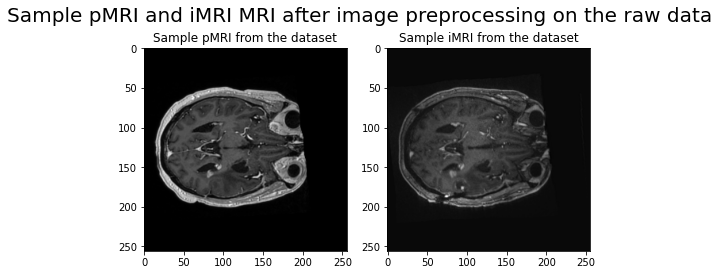

In [40]:
# visualizing preprocessed iMRI and pMRI from the input dataset
f, ax = plt.subplots(1,2, figsize=(8,8))
f.suptitle('Sample pMRI and iMRI MRI after image preprocessing on the raw data', fontsize=20, y=0.75)
ax[0].set_title('Sample pMRI from the dataset')
ax[0].imshow(sample_pMRI[0].numpy()[:, :, 0], cmap = 'gray')
ax[1].set_title('Sample iMRI from the dataset')
ax[1].imshow(sample_iMRI[0].numpy()[:, :, 0], cmap = 'gray')
plt.show()

# **Model Building**
1. Instance Normalization
2. Downsampling, Upsampling and Unet
3. Generator Building using Unet
4. Discriminator Building


### **Instance Normalization**       

Instance Normalization are specially used with Style Transfer, where Separate Normalization is performed for each sample we perform channelwise Normalization.

In [41]:
class InstanceNormalization(tf.keras.layers.Layer):
    # Initialization of Objects
    def __init__(self, epsilon=1e-5):
        # calling parent's init
        super(InstanceNormalization, self).__init__()
        self.epsilon = epsilon
    
    def build(self, input_shape):
        self.scale = self.add_weight(
            name='scale',
            shape=input_shape[-1:],
            initializer=tf.random_normal_initializer(1., 0.02),
            trainable=True)
        self.offset = self.add_weight(
            name='offset',
            shape=input_shape[-1:],
            initializer='zeros',
            trainable=True)
    
    def call(self, x):
        # Compute Mean and Variance, Axes=[1,2] ensures Instance Normalization
        mean, variance = tf.nn.moments(x, axes=[1, 2], keepdims=True)
        inv = tf.math.rsqrt(variance + self.epsilon)
        normalized = (x - mean) * inv
        return self.scale * normalized + self.offset

### **Downsample** 
- Uses Conv2D layers
- Reduces the dimension with each new layer
- Model convolution is applied to reduce the image size and increase image depth (encoder)


In [42]:
# method to downsample images using convolution, downsamples the image dimensions
def downsample(filters, size, apply_norm=True):
    initializer = tf.random_normal_initializer(0., 0.02)
    result = tf.keras.Sequential()
    # Add Conv2d layer
    result.add(tf.keras.layers.Conv2D(filters, size, strides=2, padding='same',
                                      kernel_initializer=initializer, use_bias=False))
    # Add Normalization layer
    if apply_norm:
        result.add(InstanceNormalization())
    # Add Parametric Relu Activation
    result.add(tf.keras.layers.PReLU())
    return result

### **Upsample**  
- Uses Transposed Convolution layers
- Increases the dimensions
- Transposed convolution is applied which increases the image size (decoder)

In [43]:
# method to upsample the downsampled images connected to a transformer block, upsamples the image dimension
def upsample(filters, size, apply_dropout=False):
    initializer = tf.random_normal_initializer(0., 0.02)
    result = tf.keras.Sequential()
    # Add Transposed Conv2d layer
    result.add(tf.keras.layers.Conv2DTranspose(filters, size, strides=2, padding='same',
                                               kernel_initializer=initializer, use_bias=False))
    # Add Normalization Layer
    result.add(InstanceNormalization())
    # Conditionally add Dropout layer
    if apply_dropout:
        result.add(tf.keras.layers.Dropout(0.5))
    # Add Relu Activation Layer
    result.add(tf.keras.layers.ReLU())
    return result

### **Generator**  

Generator follows **U-net architecture**  which is fairly simple architecture; however, to create the skip connections between the encoder and decoder, we will need to concatenate some layers. So the Keras Functional API is most appropriate for this purpose.

U-Net is able to localize and distinguish borders by classifying on every pixel, with both input and output images being of same size

Here, Generator generates synthetic images(iMRI to pMRI and vice versa) using given random normal initializer

## **Unets**
- Unets take images as input and translate it into another Image. <p>
- To do this they first use Downsampling on Input Image to learn the latent characteristics of input image and then use Upsampling to use this knowledge to translate it into another image. <p>
- The last layer in the downsampling process is the bottleneck layer. <p>
- Each downsampling layer (except the bottleneck layer) has a corresponding upsampling layer. <p>
- An important characteristic is the use of skip connections, which retain the background information from the downsampling layers and transfer them to the corresponding upsampling layer. Bottleneck layer, obviously, has no skip connections.

In [44]:
# Building U-net generator which is a combination of Convolution + Transposed Convolution Layers
def unet_generator():
  inputs = tf.keras.layers.Input(shape=[256,256,1]) # input layer
  # increasing the image size from (256 x 256 x 1) --> (1 x 1 x 512)
  down_stack = [
      downsample(128, 4, apply_norm=False), 
      downsample(256, 4), 
      downsample(512, 4), 
      downsample(512, 4), 
      downsample(512, 4), 
      downsample(512, 4), 
      downsample(512, 4), 
      downsample(512, 4), 
    ]
  # decreasing the image size from (1 x 1 x 512) --> (128 x 128 x 256)
  up_stack = [
      upsample(512, 4, apply_dropout=True),
      upsample(512, 4, apply_dropout=True), 
      upsample(512, 4, apply_dropout=True), 
      upsample(512, 4), 
      upsample(512, 4), 
      upsample(256, 4), 
      upsample(128, 4),
    ]
  # (125 x 128 x 256) --> (256 x 256 x 1)
  initializer = tf.random_normal_initializer(0., 0.02)
  last = tf.keras.layers.Conv2DTranspose(1, 4,
                                          strides=2,
                                          padding='same',
                                          kernel_initializer=initializer,
                                          activation='tanh') 

  x = inputs
  # skip connections is used to concatenate encoder with decoder
  skips = []
  # downsampling
  for down in down_stack:
    x = down(x)
    skips.append(x)
  skips = reversed(skips[:-1])
  # Upsampling and establishing the skip connections
  for up, skip in zip(up_stack, skips):
    x = up(x)
    x = tf.keras.layers.Concatenate()([x, skip])
  x = last(x)
  return tf.keras.Model(inputs=inputs, outputs=x) # returns U-net generator model

To summarize the U-net generator the input image (256 x 256 x 1) is increased to (1 x 1 x 512) and brought back to (256 x 256 x 1) using encoder [which learns the image irrespective of its loaction] and decoder [details are captured here] using skip connections to get precise locations, feature maps from corresponding encoder level is concatenated with output of transposed convolutional layers

## **Generators**  
Generator is a Unet Network since we want to translate iMRI images to pMRI and vice-versa.

### **Initializing the Generator**

In [45]:
# initializing the generator
generator_g = unet_generator() # iMRI images will transform to pMRI
generator_f = unet_generator() # pMRI images will transform to iMRI

generator_g learns to transform image from iMRI to pMRI

generator_f learns to transform image from pMRI to iMRI

### **Visualize Generator Model Architecture**   

In [46]:
!pip install pydot
!pip install graphviz

Looking in indexes: http://mirrors.aliyun.com/pypi/simple
Looking in indexes: http://mirrors.aliyun.com/pypi/simple


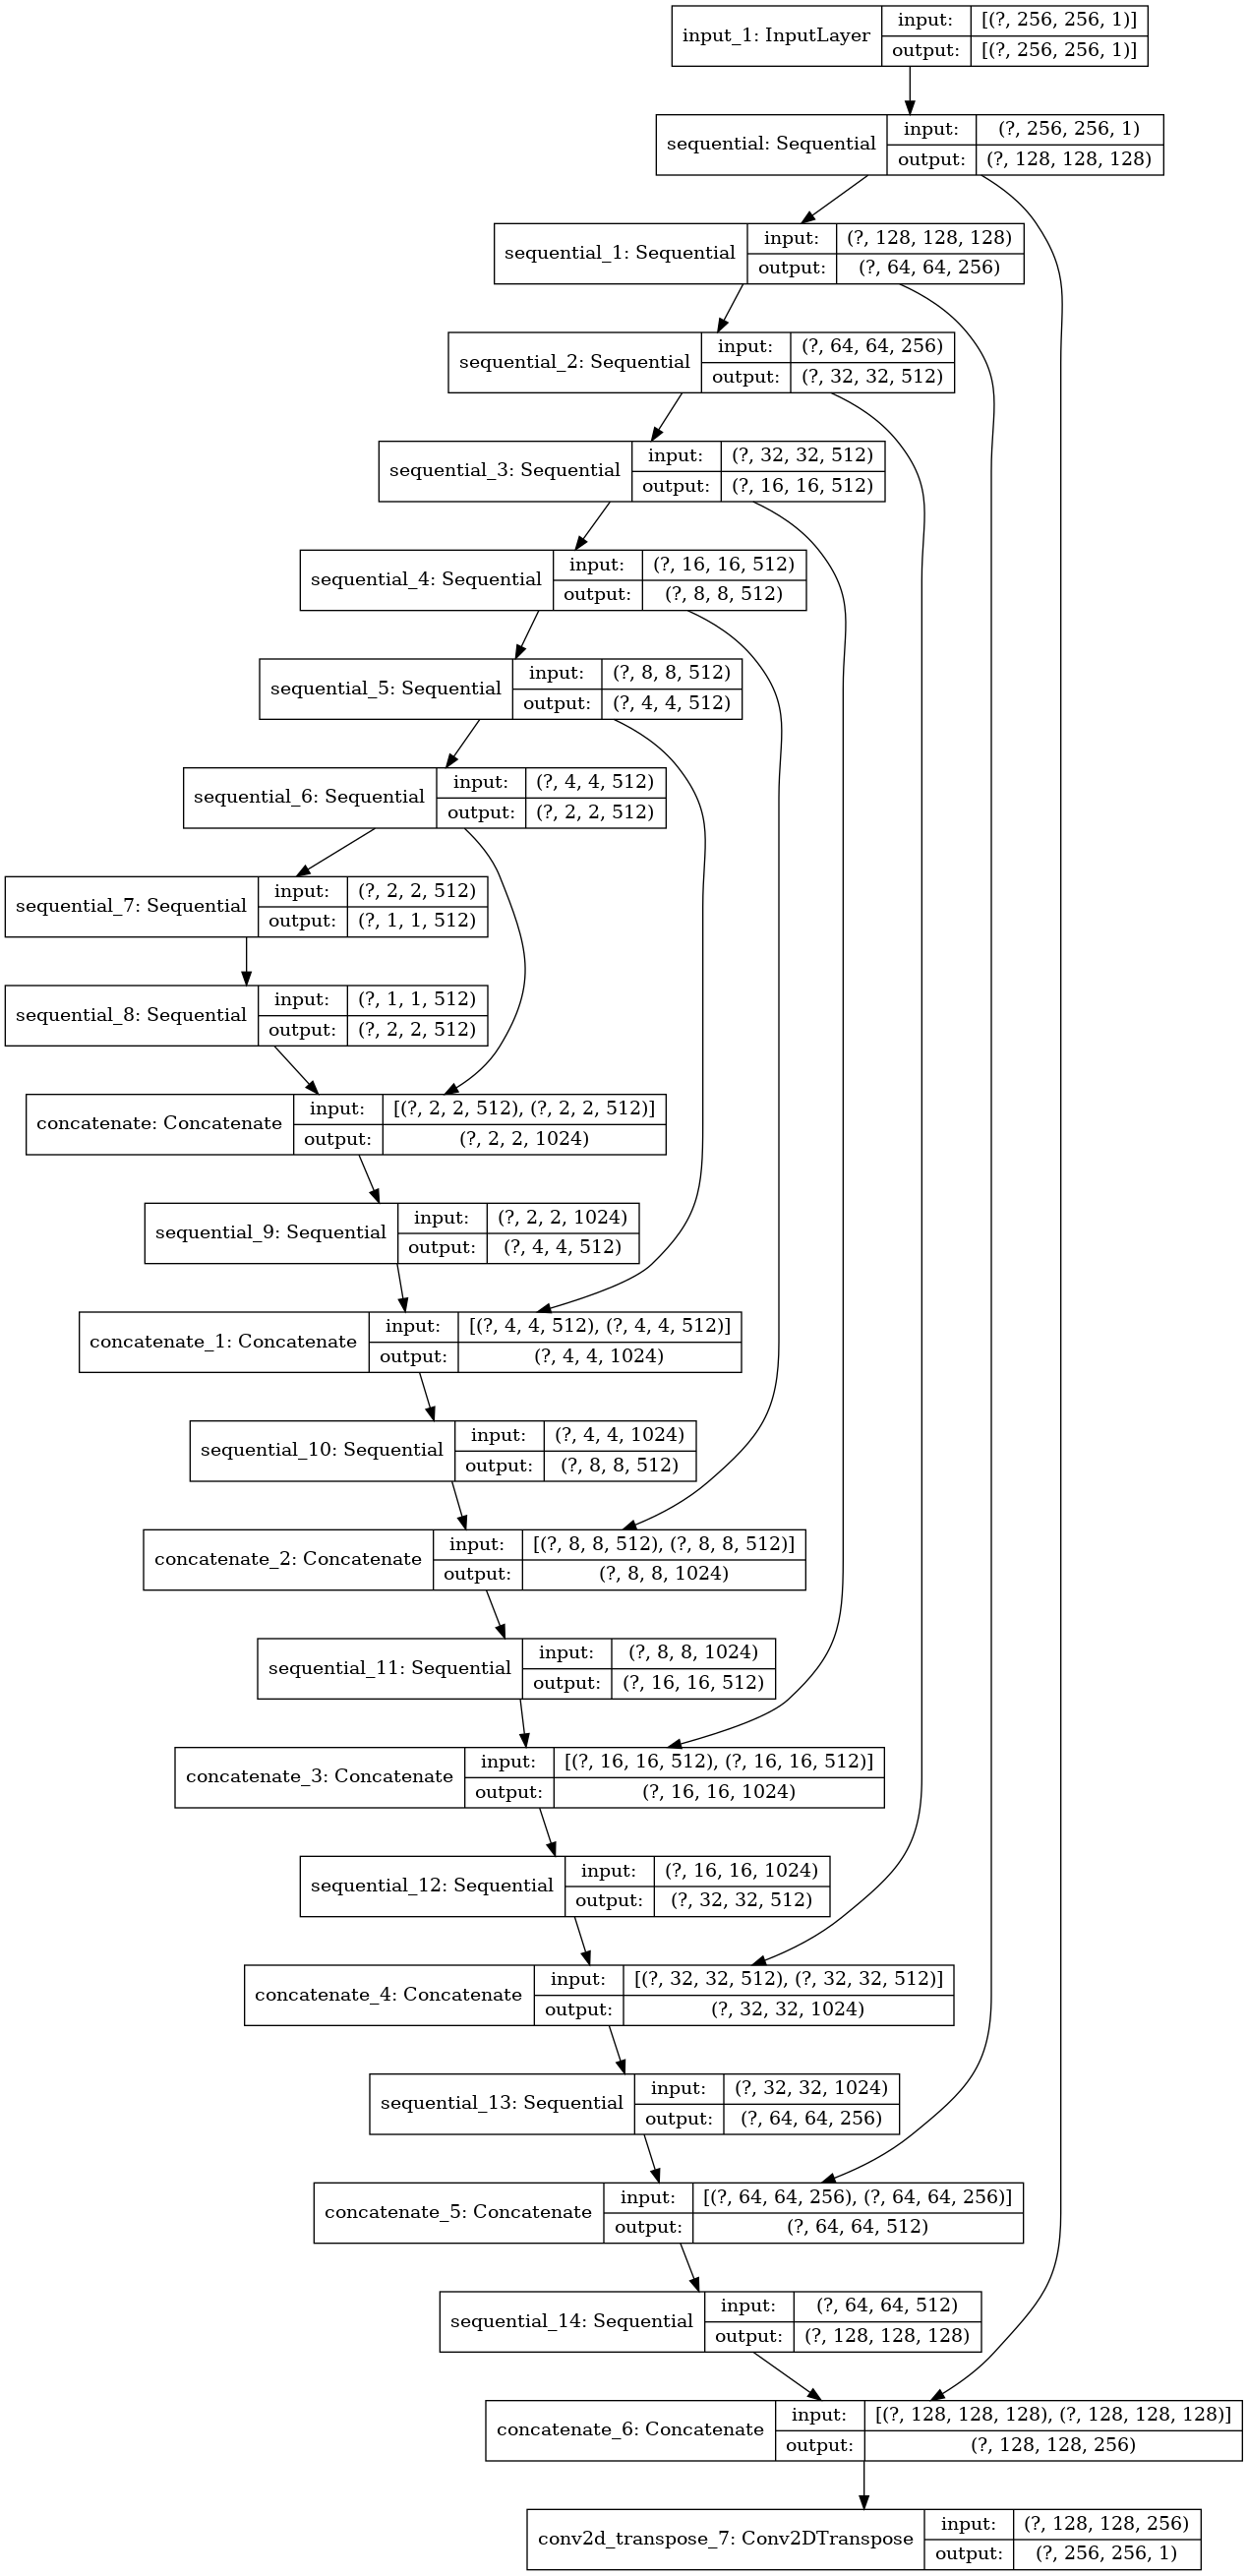

In [47]:
# Visualize generator model architecture
import pydot
plot_model(generator_g, show_shapes=True, show_layer_names=True)

### **Summarizing U-net Generator**  

# summarizing U-net Generator
generator_g.summary()

### **Plotting the Original and Generated images using created Generator**

2025-07-14 14:24:24.229684: I tensorflow/stream_executor/platform/default/dso_loader.cc:48] Successfully opened dynamic library libcudnn.so.7
2025-07-14 14:24:26.091153: I tensorflow/stream_executor/platform/default/dso_loader.cc:48] Successfully opened dynamic library libcublas.so.10


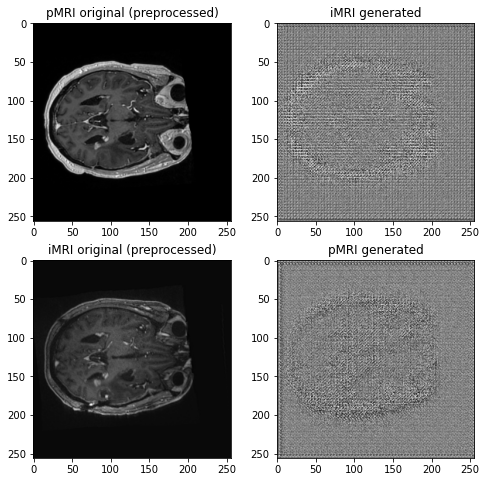

In [48]:
# plotting the original and generated images using created Generator

to_pMRI = generator_g(sample_pMRI)
to_iMRI = generator_f(sample_iMRI)
img_array = [sample_pMRI, to_pMRI, sample_iMRI, to_iMRI]
img_title = ['pMRI original (preprocessed)', 'iMRI generated', 'iMRI original (preprocessed)', 'pMRI generated']

f, ax = plt.subplots(2, 2, figsize=(8,8))
ax[0,0].set_title(img_title[0])
ax[0,0].imshow(img_array[0][0].numpy()[:, :, 0], cmap='gray')
ax[0,1].set_title(img_title[1])
ax[0,1].imshow(img_array[1][0].numpy()[:, :, 0], cmap='gray')
ax[1,0].set_title(img_title[2])
ax[1,0].imshow(img_array[2][0].numpy()[:, :, 0], cmap='gray')
ax[1,1].set_title(img_title[3])
ax[1,1].imshow(img_array[3][0].numpy()[:, :, 0], cmap='gray')
plt.show()

###  **Visualizing the U-net model(generator) using plot_model**   

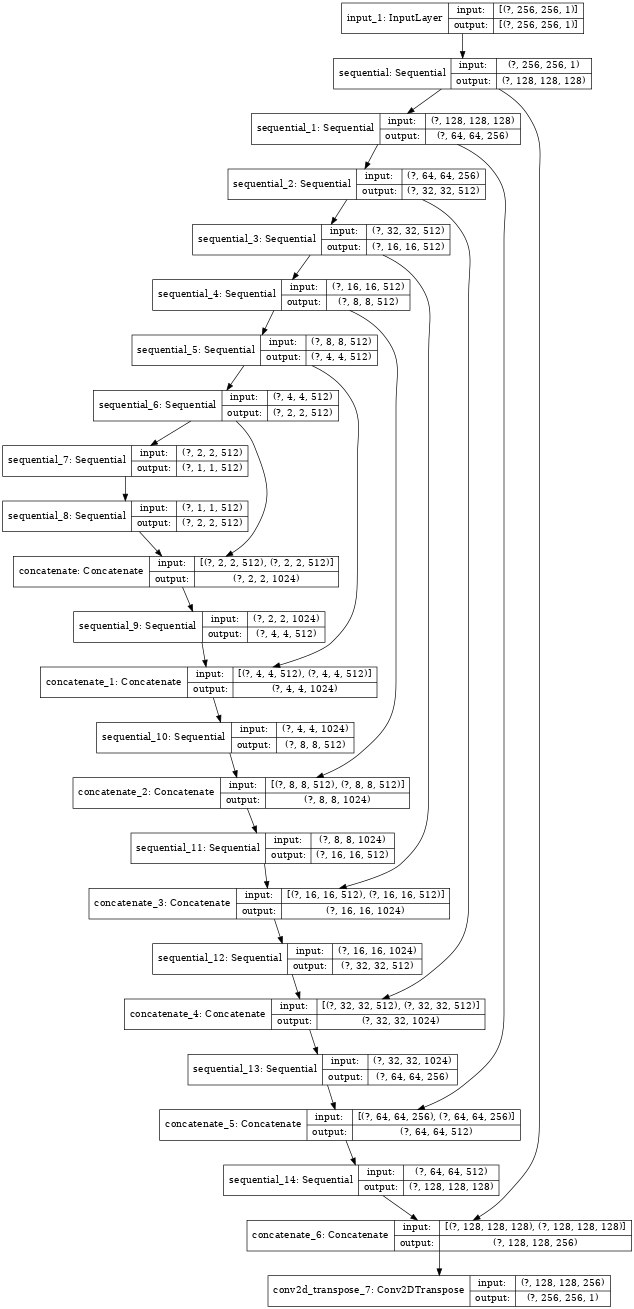

In [49]:
# visualizing the U-net model(generator) using plot_model
# explains the transformations iccured in U-net generator
# tf.keras.utils.plot_model(
#     generator_g,
#     to_file="unet_generator_model.png",
#     show_shapes=True,
#     show_dtype=True,
#     show_layer_names=True,
#     rankdir="TB",
#     expand_nested=False,
#     dpi=48)

# 可视化 U-net 模型（generator），移除 show_dtype 参数
tf.keras.utils.plot_model(
    generator_g,
    to_file="unet_generator_model.png",
    show_shapes=True,
    show_layer_names=True,
    rankdir="TB",  # 图布局方向：从上到下 (Top to Bottom)
    expand_nested=False,
    dpi=48
)

In [ ]:
## **Discriminator**     
- Discriminator is a traditional CNN, which we use to classify the Images. - It only uses Downsampling hence. Discriminator shall classify a portion of the image generated from the generator (input image) as fake or real.
- Both Discriminators have same architecture.


In [ ]:
### **CBAM**

In [1]:
import torch, torch.nn as nn, torch.nn.functional as F

# ---------- Channel Branch ----------
class MaskedChannelAttention(nn.Module):
    def __init__(self, channels, r=16):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(channels, channels//r, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(channels//r, channels, bias=False)
        )
        self.sigmoid   = nn.Sigmoid()
        self.lambda_g  = nn.Parameter(torch.tensor(1.0))

    def forward(self, x, m_y, m_g):
        B,C,H,W = x.shape
        gap = F.adaptive_avg_pool2d(x, 1).view(B, C)
        gmp = F.adaptive_max_pool2d(x, 1).view(B, C)

        # ---- mask 引导 ----
        # 避免除 0
        eps = 1e-6
        my_sum = m_y.sum((2,3)) + eps
        mg_sum = m_g.sum((2,3)) + eps
        gap_y  = (x*m_y).sum((2,3))/my_sum          # (B,C)
        gap_g  = (x*m_g).sum((2,3))/mg_sum

        stats = gap + gmp + gap_y - self.lambda_g*gap_g
        w = self.sigmoid(self.mlp(stats)).view(B,C,1,1)
        return x * w

# ---------- Spatial Branch ----------
class MaskedSpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super().__init__()
        pad = (kernel_size-1)//2
        self.conv     = nn.Conv2d(4, 1, kernel_size, padding=pad, bias=False)
        self.sigmoid  = nn.Sigmoid()
        self.lambda_g = nn.Parameter(torch.tensor(1.0))

    def forward(self, x, m_y, m_g):
        avg = x.mean(1, keepdim=True)
        mx  = x.max(1, keepdim=True)[0]
        mg  = -self.lambda_g * m_g
        m   = torch.cat([avg, mx, m_y, mg], dim=1)
        w   = self.sigmoid(self.conv(m))
        return x * w

# ---------- Parallel-CBAM ----------
class ParallelCBAM(nn.Module):
    def __init__(self, channels, r=16):
        super().__init__()
        self.ca    = MaskedChannelAttention(channels, r)
        self.sa    = MaskedSpatialAttention()
        self.alpha = nn.Parameter(torch.zeros(1))
        self.beta  = nn.Parameter(torch.zeros(1))

    def forward(self, x, m_y, m_g):
        return x + self.alpha*self.ca(x, m_y, m_g) + \
                   self.beta *self.sa(x, m_y, m_g)

In [ ]:
### 把它嵌入到Generator

In [2]:
class ResUnitWithCBAM(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(in_c, out_c, 3, 1, 1, bias=False),
            nn.InstanceNorm2d(out_c),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(out_c, out_c, 3, 1, 1, bias=False),
            nn.InstanceNorm2d(out_c)
        )
        self.cbam = ParallelCBAM(out_c)  # 添加 Parallel-CBAM 模块

    def forward(self, x, m_y, m_g):
        out = self.body(x)
        out = self.cbam(out, m_y, m_g)  # 将 CBAM 应用于特征图
        return F.leaky_relu(out + x, 0.2)
    
    
def forward(self, x, m_y, m_g):
# 编码器部分
x, skip1 = self.encoder1(x, m_y, m_g)  # 第一层编码器
x, skip2 = self.encoder2(x, m_y, m_g)  # 第二层编码器
x, skip3 = self.encoder3(x, m_y, m_g)  # 第三层编码器

# 解码器部分
x = self.decoder1(x, skip3, m_y, m_g)  # 第一层解码器
x = self.decoder2(x, skip2, m_y, m_g)  # 第二层解码器
x = self.decoder3(x, skip1, m_y, m_g)  # 第三层解码器

return x

In [ ]:
### Encoder-Block ↓2×：

In [3]:
class Down(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()
        self.res = ResUnit(in_c, out_c)
        self.pool= nn.AvgPool2d(2)

    def forward(self, x, m_y, m_g):
        out = self.res(x, m_y, m_g)
        return self.pool(out), out            # (down, skip)

In [ ]:
### Decoder-Block ↑2×（注意同步上采样 Mask）：

In [4]:
class Up(nn.Module):
    def __init__(self, in_c, skip_c, out_c):
        super().__init__()
        self.up   = nn.ConvTranspose2d(in_c, out_c, 2, 2)
        self.res  = ResUnit(out_c+skip_c, out_c)

    def forward(self, x, skip, m_y, m_g):
        x = self.up(x)
        m_y = F.interpolate(m_y, size=x.shape[2:], mode='nearest')
        m_g = F.interpolate(m_g, size=x.shape[2:], mode='nearest')
        x = torch.cat([x, skip], dim=1)
        return self.res(x, m_y, m_g)

### **Building the Discriminator**     

In [50]:
# Building the discriminator
# Discriminators only contain Convolutional layers and no Transposed Convolution is used.
def discriminator():
  initializer = tf.random_normal_initializer(0., 0.02)
  # add input layer of size (256,256,1)
  inputs = tf.keras.layers.Input(shape=[256,256, 1], name='input_image')
  x = inputs

  # add downsampling step here
  down1 = downsample(128, 4, False)(x) 
  down2 = downsample(256, 4)(down1) 
  down3 = downsample(512, 4)(down2) 
  
  # add a padding layer here
  zero_pad1 = tf.keras.layers.ZeroPadding2D()(down3) 
  conv = tf.keras.layers.Conv2D(512, 4, strides=1, kernel_initializer=initializer,
                                use_bias=False)(zero_pad1) 
  norm1 = InstanceNormalization()(conv)
  leaky_relu = tf.keras.layers.PReLU()(norm1)

  # apply zero padding layer
  zero_pad2 = tf.keras.layers.ZeroPadding2D()(leaky_relu) 
  last = tf.keras.layers.Conv2D(1, 4, strides=1, kernel_initializer=initializer)(zero_pad2) 
  return tf.keras.Model(inputs=[inputs], outputs=last) 

Discriminator uses an image patch of (30 x 30 x 1) from the generator to verify the synthetic image as real or fake

### **Initializing the Discriminators**      

In [51]:
# Initializing the discriminators
discriminator_x = discriminator() # separates real iMRI from generated iMRI
discriminator_y = discriminator() # separates real pMRI from generated pMRI

discriminator_x learns to differentiate between image iMRI and generated image iMRI.

discriminator_y learns to differentiate between image pMRI and generated image pMRI

### **Summarizing the Discriminator**       

In [52]:
# summarizing the discriminator
discriminator_x.summary()

Model: "functional_5"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_image (InputLayer)     [(None, 256, 256, 1)]     0         
_________________________________________________________________
sequential_30 (Sequential)   (None, 128, 128, 128)     2099200   
_________________________________________________________________
sequential_31 (Sequential)   (None, 64, 64, 256)       1573376   
_________________________________________________________________
sequential_32 (Sequential)   (None, 32, 32, 512)       2622464   
_________________________________________________________________
zero_padding2d (ZeroPadding2 (None, 34, 34, 512)       0         
_________________________________________________________________
conv2d_19 (Conv2D)           (None, 31, 31, 512)       4194304   
_________________________________________________________________
instance_normalization_30 (I (None, 31, 31, 512)      

### **Visualize Discriminator Model Architecture**    

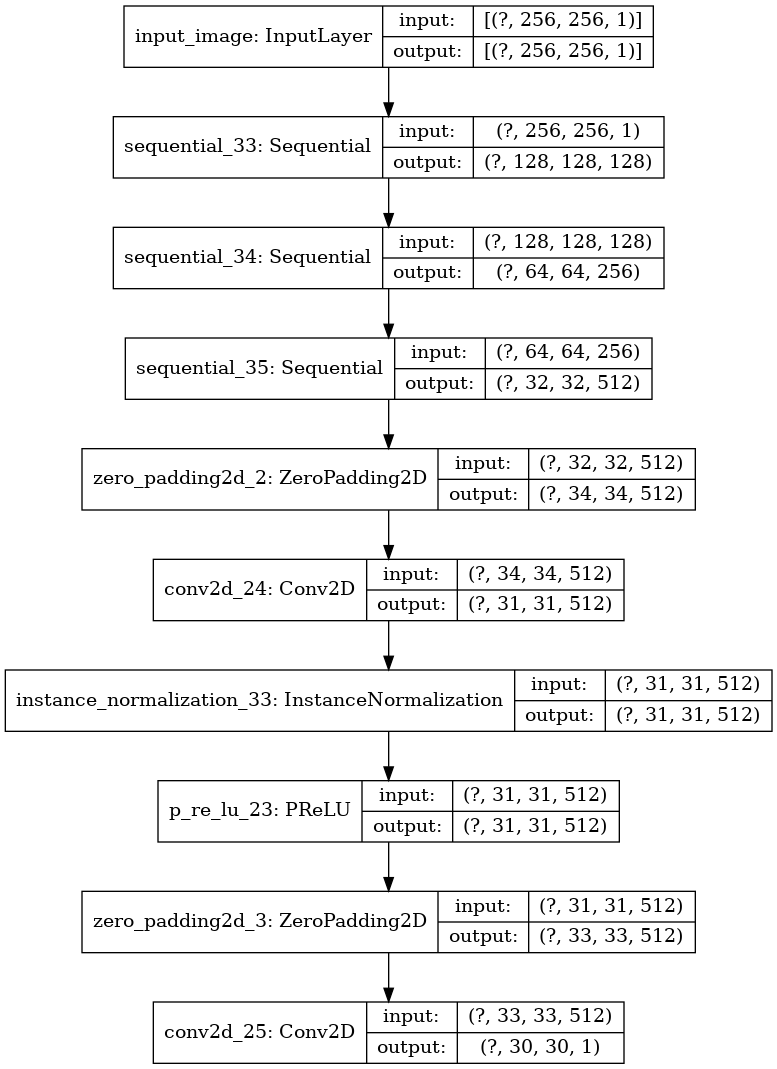

In [53]:
# Visualize discriminator model architecture
plot_model(discriminator_y, show_shapes=True, show_layer_names=True)

### **Visualising the created Discriminator Model using plot_model**   

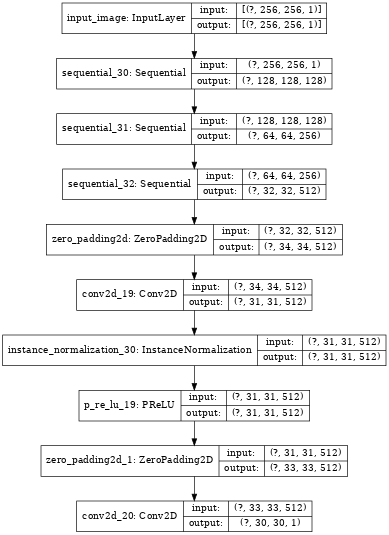

In [54]:
# visualising the created Discriminator model using plot_model
tf.keras.utils.plot_model(
    discriminator_x,
    to_file="discriminator_model.png",
    show_shapes=True,
    show_layer_names=True,
    rankdir="TB",
    expand_nested=False,
    dpi=48)

# **Model Training**  
1. Declare Loss type
2. Calculate Discriminator Loss
3. Calculate Generator Loss
4. Cycle Loss
5. Identity Loss
6. Optimizer
7. Checkpoint Initialization
8. Training Flow

### **Checking output of untrained generator**

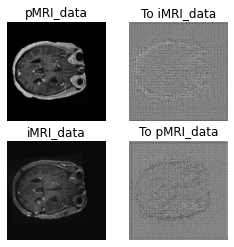

In [55]:
to_pMRI_data = generator_g(sample_pMRI)   # Generating pMRI from iMRI data
to_iMRI_data = generator_f(sample_iMRI)   # Generating iMRI from pMRI data

plt.figure(figsize=(4, 4))

imgs = [sample_pMRI, to_pMRI_data, sample_iMRI, to_iMRI_data]
title = ['pMRI_data', 'To iMRI_data', 'iMRI_data', 'To pMRI_data']

for i in range(len(imgs)):
    plt.subplot(2, 2, i+1)
    plt.title(title[i])
    plt.imshow(imgs[i][0].numpy()[:, :, 0], cmap='gray')
    plt.axis('off')
plt.show()

### **1. Declare Loss type**

- Declare Loss as **Binary Cross Entropy** , since Our Discriminator is a classifier

In [56]:
loss_fn = tf.keras.losses.BinaryCrossentropy(from_logits=True)

### **2. Discriminator Loss**    

It consists of two types of losses:
1.   **Loss on Real Data:**
        - loss function of real images which is a binary cross entropy loss and ones arrays `real_loss`
2.    **Loss on Fake Data:**
        - loss from generated (fake) images which is a binary cross entropy loss of generated images and zero arrays   `generated_loss`

**Now the `total_loss` (discriminator loss) is a sum of real_loss and generated_loss**


In [57]:
# Discriminator adversarial loss

def discriminator_loss(real, generated):
  real_loss = loss_fn(tf.ones_like(real), real)
  generated_loss = loss_fn(tf.zeros_like(generated), generated)
  total_disc_loss = real_loss + generated_loss
  return total_disc_loss * 0.5   # mean of losses

### **3. Generator Loss**    

- It has only one type of loss - Discriminator Loss on Generated data
- It is a binary cross entropy loss of the synthetic images and an array of ones

In [58]:
# method to obtain generator loss
def generator_loss(generated):
  return loss_fn(tf.ones_like(generated), generated)

### **4. Cycle Consistency Loss**   

- When we use both of Generators sequentially on a Input Image, we get Cycle Image and the L1 Loss between these two is called Cycle consistency Loss.

- It is the reduced mean of difference between real and synthetic image. Suppose if the synthetic image is translated back it should be close to original image

In [59]:
LAMBDA = 10 # learning rate
LAMBDA_TUMOR = 10.0   # 额外约束肿瘤保持术中状态的权重，你可以之后调大小
# method to calculate cycle consitency loss
def cycle_consistency_loss(real_image, cycled_image):
  cyc_loss = tf.reduce_mean(tf.abs(real_image - cycled_image))  # Averages out all values in the input
  return LAMBDA * cyc_loss # Weight of 10 used as contribution of cycle loss to total loss. This is a hyperparameter.

def cycle_consistency_loss(real_image, cycled_image, non_tumor_mask):
    """
    real_image, cycled_image: [B, H, W, 1]
    non_tumor_mask: [B, H, W, 1]，非肿瘤区域=1，肿瘤区域=0
    """
    l1 = tf.abs(real_image - cycled_image) * non_tumor_mask
    # 用 mask 后再平均
    return LAMBDA * tf.reduce_mean(l1)

### **5. Identity Loss**   
When we provide input image to the Generator such that no translation is needed because the image is already transformed, the difference should be minimal between original and generated image. Here also we take L1 Loss between input and output image.

In [60]:
# method to calculate identity loss
def identity_loss(real_image, same_image):
  loss = tf.reduce_mean(tf.abs(real_image - same_image)) # Averages out all values in the input
  return LAMBDA * 0.5 * loss


def identity_loss(real_image, same_image, non_tumor_mask):
    """
    identity loss 也只在非肿瘤区域算，避免强迫肿瘤恢复
    """
    l1 = tf.abs(real_image - same_image) * non_tumor_mask
    return LAMBDA * 0.5 * tf.reduce_mean(l1)

### **6. Optimizer**   
Adam optimizer is used in both generator and discriminator outputs

In [61]:
generator_g_optimizer = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)
generator_f_optimizer = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)

discriminator_x_optimizer = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)
discriminator_y_optimizer = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)

### **7. Checkpoint Initialization**     

- Initialize checkpoints to save models
- Checkpoint - object which periodically writes checkpoints to disk.
- CheckpointManager helps in managing multiple checkpoints



In [62]:
# number of epochs for the model to be trained
EPOCHS = 100

In [63]:
# Directory to keep Checkpoints at each epoch
if not os.path.isdir('training_checkpoints'):
    os.mkdir('training_checkpoints')

checkpoint_path = "./training_checkpoints"

checkpoint = tf.train.Checkpoint(generator_g=generator_g,
                           generator_f=generator_f,
                           discriminator_x=discriminator_x,
                           discriminator_y=discriminator_y,
                           generator_g_optimizer=generator_g_optimizer,
                           generator_f_optimizer=generator_f_optimizer,
                           discriminator_x_optimizer=discriminator_x_optimizer,
                           discriminator_y_optimizer=discriminator_y_optimizer)

checkpoint_manager = tf.train.CheckpointManager(checkpoint, checkpoint_path, max_to_keep=EPOCHS)

# if a checkpoint exists, restore the latest checkpoint.
if checkpoint_manager.latest_checkpoint:
  checkpoint.restore(checkpoint_manager.latest_checkpoint)
  print('Latest checkpoint restored!!')

Latest checkpoint restored!!


In [64]:
# Function to show Images output by Generators while Training
def generate_images(model1, test_inpuiMRI, model2, test_inpupMRI):
  prediction1 = model1(test_inpuiMRI) # Image Translation from iMRI to pMRI
  prediction2 = model2(test_inpupMRI) # Image Translation from pMRI to iMRI
  plt.figure(figsize=(12, 8))
  display_list = [test_inpuiMRI[0], prediction1[0], test_inpupMRI[0], prediction2[0]]
  title = ['Input pMRI', 'Predicted iMRI - Epoch ' + str(epoch+1), 'Input iMRI', 'Predicted pMRI - Epoch ' + str(epoch+1)]
  for i in range(4):
    plt.subplot(1, 4, i+1)
    plt.title(title[i])
    plt.imshow(display_list[i].numpy()[:, :, 0], cmap='gray')
    plt.axis('off')

  plt.savefig('image_at_epoch_{:04d}.png'.format(epoch+1))
  plt.show()

## **8. Training Flow**    

### **Model Training Steps:**       

The training consists of four broad steps

1. Get the predictions — The generator and discriminator modules are used to get the predictions
2. Calculate the loss — Various loss functions defined above are used to calculate the losses
3. Calculate the gradients using backpropagation
4. Apply the gradients to the optimizer — Adam optimizer as defined in the original paper is used for optimization

### **Training Step Function**   

In [65]:
@tf.function
def train_step(real_x, real_y, mask_x, mask_y):
    """
    real_x: iMRI/iMRI,   形状 [B,256,256,1]
    real_y: pMRI/pMRI,   形状 [B,256,256,1]
    mask_x: iMRI 的肿瘤/切除掩码, 1=肿瘤, 0=正常
    mask_y: pMRI 的肿瘤掩码，如果暂时没有，可以用 tf.zeros_like(real_y)
    """
    # 确保是 float32
    mask_x = tf.cast(mask_x, tf.float32)
    mask_y = tf.cast(mask_y, tf.float32)

    non_tumor_x = 1.0 - mask_x  # 非肿瘤区域
    non_tumor_y = 1.0 - mask_y

    with tf.GradientTape(persistent=True) as tape:
        # ===== 1. 生成 =====
        fake_y = generator_g(real_x, training=True)      # X -> Y (iMRI -> pMRI)
        cycled_x = generator_f(fake_y, training=True)    # X' -> X

        fake_x = generator_f(real_y, training=True)      # Y -> X
        cycled_y = generator_g(fake_x, training=True)    # Y' -> Y

        # ===== 2. identity 输出 =====
        same_x = generator_f(real_x, training=True)      # X 保持 X
        same_y = generator_g(real_y, training=True)      # Y 保持 Y

        # ===== 3. 判别器输出 =====
        disc_real_x = discriminator_x(real_x, training=True)
        disc_real_y = discriminator_y(real_y, training=True)
        disc_fake_x = discriminator_x(fake_x, training=True)
        disc_fake_y = discriminator_y(fake_y, training=True)

        # ===== 4. G 的对抗损失（不改）=====
        gen_g_loss = generator_loss(disc_fake_y)   # X->Y
        gen_f_loss = generator_loss(disc_fake_x)   # Y->X

        # ===== 5. masked cycle loss：只在非肿瘤区域约束循环一致 =====
        cycle_x_loss = cycle_consistency_loss(real_x, cycled_x, non_tumor_x)
        cycle_y_loss = cycle_consistency_loss(real_y, cycled_y, non_tumor_y)
        total_cycle_loss = cycle_x_loss + cycle_y_loss

        # ===== 6. masked identity loss：只在非肿瘤区域算 =====
        id_y_loss = identity_loss(real_y, same_y, non_tumor_y)  # 给 G:X->Y 用
        id_x_loss = identity_loss(real_x, same_x, non_tumor_x)  # 给 F:Y->X 用

        # ===== 7. 额外：在肿瘤区域保持“术中状态”的约束（只给 G 用）=====
        # 希望 G(iMRI) 在 mask_x==1 区域不要和 real_y 一样长回肿瘤，
        # 而是尽量接近原来的 iMRI 结构
        tumor_preserve_loss = tf.reduce_mean(
            mask_x * tf.abs(fake_y - real_x)
        )  # 只在 tumor 区算 L1

        # ===== 8. 汇总生成器的损失 =====
        total_gen_g_loss = gen_g_loss \
                           + total_cycle_loss \
                           + id_y_loss \
                           + LAMBDA_TUMOR * tumor_preserve_loss   # ⭐ 关键

        total_gen_f_loss = gen_f_loss \
                           + total_cycle_loss \
                           + id_x_loss

        # ===== 9. 判别器损失（可以保持原来的写法）=====
        disc_x_loss = discriminator_loss(disc_real_x, disc_fake_x)
        disc_y_loss = discriminator_loss(disc_real_y, disc_fake_y)

    # ===== 10. 反向传播 & 更新参数（你的原代码这部分基本不用改变量名）=====
    generator_g_gradients = tape.gradient(total_gen_g_loss,
                                          generator_g.trainable_variables)
    generator_f_gradients = tape.gradient(total_gen_f_loss,
                                          generator_f.trainable_variables)

    discriminator_x_gradients = tape.gradient(disc_x_loss,
                                              discriminator_x.trainable_variables)
    discriminator_y_gradients = tape.gradient(disc_y_loss,
                                              discriminator_y.trainable_variables)

    generator_g_optimizer.apply_gradients(
        zip(generator_g_gradients, generator_g.trainable_variables))
    generator_f_optimizer.apply_gradients(
        zip(generator_f_gradients, generator_f.trainable_variables))

    discriminator_x_optimizer.apply_gradients(
        zip(discriminator_x_gradients, discriminator_x.trainable_variables))
    discriminator_y_optimizer.apply_gradients(
        zip(discriminator_y_gradients, discriminator_y.trainable_variables))

    return {
        'total_gen_g_loss': total_gen_g_loss,
        'total_gen_f_loss': total_gen_f_loss,
        'disc_x_loss': disc_x_loss,
        'disc_y_loss': disc_y_loss,
        'tumor_preserve': tumor_preserve_loss
    }


### **Save Finalized Model**        

In [66]:
# method to save finalized model trained and evaluated for further use
def final_model_save(epoch, generator_g, generator_f):
  model_save_path = 'model_save/'
  iMRI_to_pMRI_model = model_save_path + 'iMRI_to_pMRI_final_model.h5'
  generator_g.save(iMRI_to_pMRI_model)
  pMRI_to_iMRI_model = model_save_path + 'pMRI_to_iMRI_final_model.h5'
  generator_f.save(pMRI_to_iMRI_model)
  print('trained models saved at %06d' % (epoch+1))

### **Train the CycleGAN Model for several Epochs**    
Loop training function for number of epochs and also show the output at each step.

In [67]:
# Declaring number of epochs of training
EPOCHS = 100

可使用 GPU 进行训练，共检测到 1 块 GPU。
已设置使用第一块 GPU 进行训练。
Epoch 1/100, Generator_G_loss: 5.8035, Generator_F_loss: 4.2128, Discriminator_X_loss: 0.0981, Discriminator_Y_loss: 0.1262.


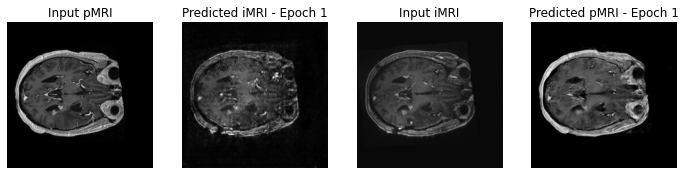

Time taken in 30 seconds for epoch 1

Epoch 2/100, Generator_G_loss: 4.5349, Generator_F_loss: 5.1560, Discriminator_X_loss: 0.3251, Discriminator_Y_loss: 0.2135.


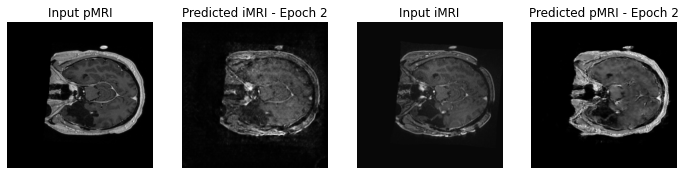

Time taken in 30 seconds for epoch 2

Epoch 3/100, Generator_G_loss: 1.5216, Generator_F_loss: 4.5666, Discriminator_X_loss: 0.1707, Discriminator_Y_loss: 0.9163.


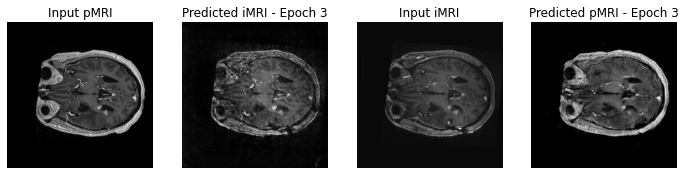

Time taken in 30 seconds for epoch 3



In [ ]:
# training the model
import tensorflow as tf
import time
import os

# 查看是否存在可用的 GPU（如果有多块 GPU，也可指定哪块）
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"可使用 GPU 进行训练，共检测到 {len(gpus)} 块 GPU。")
    try:
        # 设置仅使用第一块 GPU 的示例
        tf.config.set_visible_devices(gpus[0], 'GPU')
        print("已设置使用第一块 GPU 进行训练。")
    except RuntimeError as e:
        # 在程序已初始化张量流时再设置设备会报错
        print(e)
else:
    print("未检测到可用 GPU，将使用 CPU 进行训练。")
# Declaring number of epochs of training
EPOCHS = 100

for epoch in range(EPOCHS):
  start = time.time() 
  for image_x, image_y in tf.data.Dataset.zip((iMRI, pMRI)): # preprocessed input
    losses_dict = train_step(image_x, image_y)
    # 这里可视需求打印各类损失
    # print(f"Epoch {epoch+1}/{EPOCHS}, "
    #       f"Generator_G_loss: {losses_dict['total_gen_g_loss'].numpy():.4f}, "
    #       f"Generator_F_loss: {losses_dict['total_gen_f_loss'].numpy():.4f}, "
    #       f"Discriminator_X_loss: {losses_dict['disc_x_loss'].numpy():.4f}, "
    #       f"Discriminator_Y_loss: {losses_dict['disc_y_loss'].numpy():.4f}.")
  if (epoch + 1) % 1 == 0:
    print(f"Epoch {epoch+1}/{EPOCHS}, "
          f"Generator_G_loss: {losses_dict['total_gen_g_loss'].numpy():.4f}, "
          f"Generator_F_loss: {losses_dict['total_gen_f_loss'].numpy():.4f}, "
          f"Discriminator_X_loss: {losses_dict['disc_x_loss'].numpy():.4f}, "
          f"Discriminator_Y_loss: {losses_dict['disc_y_loss'].numpy():.4f}.")
    
     # 从训练数据集中随机获取新的样本
    sample_pMRI = next(iter(iMRI))  # 随机选择一个批次中的 iMRI 样本
    sample_iMRI = next(iter(pMRI))  # 随机选择一个批次中的 pMRI 样本
        
        
    generate_images(generator_g, sample_pMRI, generator_f, sample_iMRI) # generates input and syntetic images
  if (epoch + 1) % 10 == 0:
    checkpoint_save_path = checkpoint_manager.save() # checkpoint saved for every 10 epochs in the given path
    print('Checkpoint restored for epoch {} at {}'.format(epoch+1, checkpoint_save_path))
  if (epoch + 1) == EPOCHS:
    final_model_save(epoch, generator_g, generator_f) # the last model is saved n the given path for further use
  print('Time taken in {} seconds for epoch {}\n'.format(round(time.time()-start),epoch + 1))

### **Result:**   
After 100 epochs, the results are pretty good. The predicted images have a good likeness to their respective input image in terms of content, while having the style of the other image type.

- Predicted pMRI has the features of input iMRI in the style of pMRI.
- Predicted iMRI has the features of input pMRI in the style of iMRI.

### **Checking Trained Model**  

In [ ]:
# check the trained model on different images and check the output
import itertools
for (iMRI,pMRI) in itertools.zip_longest(iMRI.take(10), pMRI.take(10)):
  generate_images(generator_g, iMRI, generator_f, pMRI)

## **Testing the Final Model**   
Verifying the model by converting the synthetic images back to original and comparing the input image (verifying cycle consistency)

In [ ]:
# view synthetic images 
def compare_images(model_1, model_2, input):
  synthetic_image = model_1(input)
  reconstructed_image = model_2(synthetic_image)
  img_array = [input[0], synthetic_image[0], reconstructed_image[0]]
  img_title = ['Input Image', 'Synthetic Image', 'Reconstructed(cycled) Image']
  plt.figure(figsize=(12,9))
  for i in range(3):
    plt.subplot(1, 3, i+1)
    plt.title(img_title[i])
    plt.imshow(img_array[i].numpy()[:, :, 0], cmap='gray')
  plt.show()

In [ ]:
from keras.models import load_model

custom_object = {'InstanceNormalization': InstanceNormalization} # custom_objects argument

# load models
model_1 = load_model('model_save/iMRI_to_pMRI_final_model.h5', custom_object)
model_2 = load_model('model_save/pMRI_to_iMRI_final_model.h5', custom_object)

Using iMRI data

iMRI (input)  →  pMRI (synthetic)  →  iMRI (reconstructed)

In [ ]:
compare_images(model_1, model_2, sample_iMRI)

Using pMRI data

pMRI (input)  →  iMRI (synthetic)  →  pMRI (reconstructed)

In [ ]:
compare_images(model_2, model_1, sample_pMRI)